# 3. Beyond Mecca and Medina: is there a chronological signal?

Notebook 2 trained models on labels. The trouble is that the labels are the thing in dispute. This notebook asks a different question:

> If we give a computer **no labels at all**, does the text sort itself into an order, and does that order resemble one that scholars have proposed?

This is the logic of Behnam Sadeghi's "The Chronology of the Qurʾān: A Stylometric Research Program" (*Arabica*, 2011), and of Nicolai Sinai's use of mean verse length. If several *independent* measures all sort the surahs the same way, it is hard to explain that agreement except by a real development over time.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd
import matplotlib.pyplot as plt
from surahs import load_verses, load_surah_texts
from surahs.chronology import (rank_correlations, morpheme_profile, pca_chronology,
                               within_period_correlations, chunk_verses)
from surahs.translit import translit
from surahs.plotting import PERIOD_STYLE, style_axes

surahs = load_surah_texts()

## 3.1 Rank correlation

**Spearman's rho** asks how similarly two lists *rank* the same items. +1 means identical order, 0 means unrelated, −1 means reversed. We compare mean verse length (MVL) with Nöldeke's order and with the Cairo order.

In [2]:
rank_correlations(columns=("mvl",)).round(3)

,measure,against,spearman_rho,p_value,n_surahs
0,mvl,noldeke_order,0.905,0.0,114
1,mvl,cairo_order,0.694,0.0,114


MVL agrees with Nöldeke (rho ≈ 0.9) much more closely than with the Cairo order (≈ 0.7). Remember the circularity from notebook 1: Nöldeke used style, length included, to build his order. So the next step is to try a measure Nöldeke did *not* use.

## 3.2 A measure nobody designed: common-word frequencies

We count how often each surah uses the 100 commonest lemmas. Most of them are small grammatical words: *wa* (and), *fa* (so), *inna* (indeed), *alladhī* (who/which), *lā* (not). Writers, and speakers, rarely choose these consciously, which is why stylometrists like them.

Then we use **principal component analysis (PCA)**, a standard technique that finds the single direction along which the surahs differ most. It is told nothing about Mecca, Medina or Nöldeke. Its first component, PC1, is one number per surah.

Very short surahs give noisy frequency estimates (a 20-word surah cannot tell us how often its author says "that"), so we keep surahs of at least 150 words.

In [3]:
scores, pca, loadings = pca_chronology(n_features=100, min_words=150)
print(len(scores), "surahs;", f"PC1 explains {pca.explained_variance_ratio_[0]:.1%} of the variation")
rank_correlations(scores, ("PC1", "mvl")).round(3)

79 surahs; PC1 explains 8.4% of the variation


,measure,against,spearman_rho,p_value,n_surahs
0,PC1,noldeke_order,0.909,0.0,79
1,PC1,cairo_order,0.567,0.0,79
2,mvl,noldeke_order,0.952,0.0,79
3,mvl,cairo_order,0.555,0.0,79


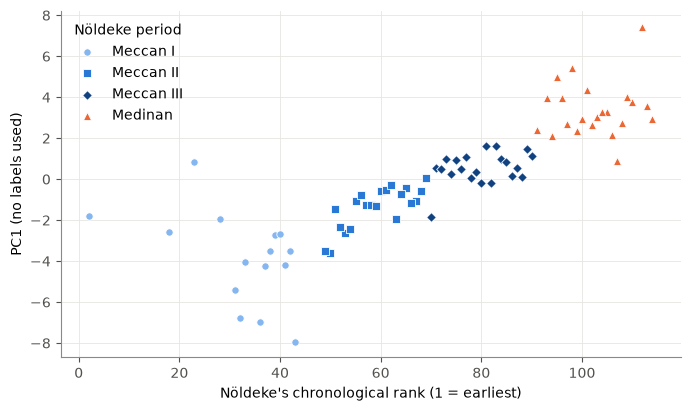

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for period, st in PERIOD_STYLE.items():
    g = scores[scores.noldeke_period == period]
    ax.scatter(g.noldeke_order, g.PC1, label=period, **st)
ax.set_xlabel("Nöldeke's chronological rank (1 = earliest)"); ax.set_ylabel("PC1 (no labels used)")
style_axes(ax); ax.legend(frameon=False, title="Nöldeke period");

What *is* PC1? The loadings show which lemmas push a surah towards each end.

In [5]:
lo = loadings.PC1.sort_values()
pd.DataFrame({"early end": [f"{translit(w)} ({w})" for w in lo.index[:12]],
              "late end": [f"{translit(w)} ({w})" for w in lo.index[::-1][:12]]})

,early end,late end
0,yawm (يَوْم),allāh (اللَّه)
1,rabb (رَبّ),ʾāmana (آمَنَ)
2,f (ف),rasūl (رَسُول)
3,khalaqa (خَلَقَ),ʾin (إِن)
4,ʾ (أ),ʿalīm (عَلِيم)
5,kadhdhaba (كَذَّبَ),y (ي)
6,ʾidh (إِذ),w (و)
7,al (ال),alladhī (الَّذِي)
8,bal (بَل),kafara (كَفَرَ)
9,ʾinn (إِنّ),qalb (قَلْب)


**Question 3.1.** PC1 mixes grammar words with content words like *Allāh*, *āmana* (believe) and *rasūl* (messenger). Does the presence of content words weaken the argument that this is an "unconscious" stylistic signal? How might you build a profile from grammar words only? (Try it: `morpheme_profile` returns a table you can filter.)

## 3.3 Inside each period

A measure could separate early from late without saying anything about order *within* a period. Does PC1 or MVL still track Nöldeke's sequence inside each of his four periods?

In [6]:
pd.concat([within_period_correlations(scores, "PC1").assign(measure="PC1"),
           within_period_correlations(surahs, "mvl").assign(measure="MVL")]).round(3)

,period,n_surahs,spearman_rho,p_value,measure
0,Meccan I,15,-0.486,0.066,PC1
1,Meccan II,21,0.753,0.000,PC1
2,Meccan III,21,0.256,0.263,PC1
3,Medinan,22,0.082,0.717,PC1
0,Meccan I,48,0.207,0.157,MVL
1,Meccan II,21,0.862,0.000,MVL
2,Meccan III,21,0.871,0.000,MVL
3,Medinan,24,0.398,0.054,MVL


Within Meccan II and III, MVL tracks Nöldeke's order closely. Nöldeke's ordering *inside* a period rests largely on stylistic impressions, verse length among them, so the circularity warning applies with full force here. PC1, which Nöldeke never computed, is the fairer test. Within Meccan I and Medinan the signals are weak. This is where scholars genuinely disagree, and where Nöldeke's fine ordering carries the least weight.

**Question 3.2.** Sinai argues that MVL can give a *rough* relative chronology but that we should not trust small differences in rank. Do these results support that caution? Why?

## 3.4 Long surahs are not uniform

A long surah like al-Baqara (2) may combine material from different moments. Sadeghi therefore cuts long surahs into blocks of roughly equal size. Here we cut every surah into blocks of about 300 words and plot each block's MVL for a few long surahs.

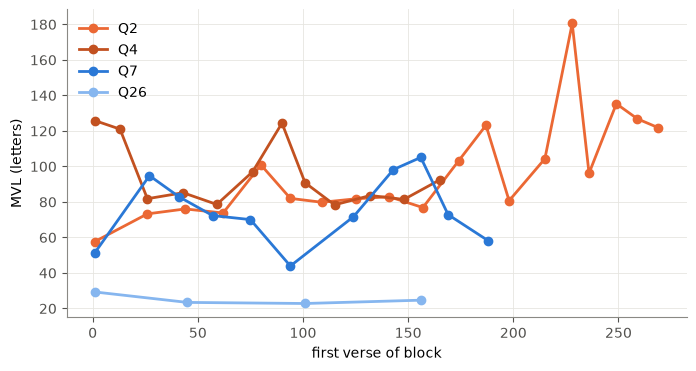

In [7]:
blocks = chunk_verses(load_verses(), words_per_chunk=300)
fig, ax = plt.subplots(figsize=(8, 4))
for n, st in zip([2, 4, 7, 26], ["#eb6834", "#c25120", "#2a78d6", "#86b6ef"]):
    b = blocks[blocks.surah == n]
    ax.plot(b.ayah_start, b.mvl, marker="o", color=st, lw=2, label=f"Q{n}")
ax.set_xlabel("first verse of block"); ax.set_ylabel("MVL (letters)")
style_axes(ax); ax.legend(frameon=False);

**Question 3.3.** Which surah varies most internally? Find the block where its MVL changes sharply and read those verses in English. Is there an obvious change of subject?

## 3.5 Four periods instead of two

Finally, a supervised model trained on Nöldeke's four periods. Read the confusion matrix row by row: each row is what Nöldeke says, each column what the model says. Numbers off the diagonal are disagreements.

In [8]:
from surahs.experiments import period_classifier
per_surah, confusion = period_classifier(load_verses())
confusion

model says,Meccan I,Meccan II,Meccan III,Medinan
Nöldeke says,,,,
Meccan I,40,7,0,1
Meccan II,2,18,1,0
Meccan III,0,1,20,0
Medinan,1,0,0,23


**Question 3.4.** Which neighbouring periods does the model confuse most? Is that a failure of the model, or evidence that Nöldeke's boundaries (48 / 21 / 21 / 24 surahs) are sharper than the text itself?